# Code for Animation

In [1]:
# Licensing Information: You are free to use or extend this file for
# educational purposes provided that (1) you retain this notice, and
# (2) you provide clear attribution to the University of Melbourne,
# including a link to https://cis.unimelb.edu.au.
#
# This file was created as part of teaching material for COMP90038
# August 2021, derived from material created in January 2020 for
# the same subject

# An annoying Colab issue:
# matplotlib 3.2 seems to be the default, so we tell it to install
# a newer version. This will cause an error when you first run it,
# telling you that you need to restart the runtime. After seeing
# that error choose Runtime -> Restart runtime from the menu above.
# Then execute this part again and things should work OK.
!pip install --upgrade matplotlib networkx
!wget http://people.eng.unimelb.edu.au/tobym/comp90038/algovis.py
from algovis import *

  Using cached matplotlib-3.9.1-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (11 kB)
  Using cached networkx-3.3-py3-none-any.whl.metadata (5.1 kB)
  Using cached contourpy-1.2.1-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (5.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.53.1-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (162 kB)
  Using cached kiwisolver-1.4.5-cp310-cp310-manylinux_2_12_x86_64.manylinux2010_x86_64.whl.metadata (6.4 kB)
  Using cached numpy-2.0.0-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (60 kB)
  Using cached pillow-10.4.0-cp310-cp310-manylinux_2_28_x86_64.whl.metadata (9.2 kB)
  Using cached pyparsing-3.1.2-py3-none-any.whl.metadata (5.1 kB)
Using cached matplotlib-3.9.1-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (8.3 MB)
Using cached networkx-3.3-py3-none-any.whl (1.7 MB)
Using cached contourpy-1.2.1-cp310-

# Euclid’s GCD

In [2]:
# The function computes GCD of two integer values using Euclid's fomula
def EuclidGCD(m,n):
    snapshot()
    while n != 0:
        r = m % n
        m = n
        n = r
        snapshot()
    return m

clear_frames()
m=24
n=60
EuclidGCD(m,n)
show_animation(size=[8,3])

# Brute force GCD

In [3]:
# The function computes GCD of two integer values in Brute Force way
def BruteForceGCD(m,n):
    r = min(m,n)
    snapshot()
    while r != 0:
        if m % r == 0 and n % r == 0:
            return r
        r = r -1
        snapshot()

clear_frames()
m=24
n=60
BruteForceGCD(m,n)
show_animation(size=[8,3])

# Runtime Euclid’s Vs  BruteForce GCD

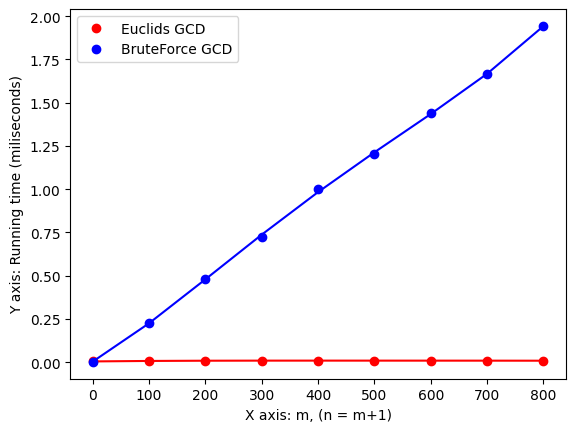

In [4]:
import numpy as np
import time
import matplotlib.pyplot as plt

# This functions compares the runtime of Euclid's GCD and BruteForce GCD
def runtimeGCD():
    mvals = np.linspace(0, 800, 9, dtype=int) #8000000
    #print(mvals)
    tE = []
    tB = []
    for m in mvals:
        start_time = time.time()
        EuclidGCD(m,m+1)
        end_time = time.time()
        tE.append(end_time-start_time)

        start_time = time.time()
        BruteForceGCD(m,m+1)
        end_time = time.time()
        tB.append(end_time-start_time)

    #print("Runtime for Euclid's GCD:", tE)
    #print("Runtime for BruteForce GCD:", tB)

    plt.plot(mvals, tE, 'or', label='Euclids GCD');
    plt.xlabel("X axis: m, (n = m+1)")
    plt.ylabel("Y axis: Running time (miliseconds)")

    degree = 4
    coeffs = np.polyfit(mvals, tE, degree)
    p = np.poly1d(coeffs)
    plt.plot(mvals, [p(m) for m in mvals], '-r')

    plt.plot(mvals, tB, 'ob', label='BruteForce GCD');
    degree = 4
    coeffs = np.polyfit(mvals, tB, degree)
    p = np.poly1d(coeffs)
    plt.plot(mvals, [p(m) for m in mvals], '-b')
    plt.legend()

runtimeGCD()
